#PREPROCESSING


In [ ]:
import pandas as pd                                                                   # pandas
from sklearn.model_selection import train_test_split                                  # train test split
from sklearn.compose import ColumnTransformer                                         # column transformer
from sklearn.preprocessing import OneHotEncoder                                       # one-hot encode
from sklearn.preprocessing import StandardScaler                                      # normalize
from sklearn.neighbors import KNeighborsClassifier                                    # knn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score) # metrics
from sklearn.metrics import classification_report                                     # classification report
from sklearn.metrics import ConfusionMatrixDisplay                                    # error matrix
import matplotlib.pyplot as plt                                                       # matplotlib
import numpy as np                                                                    # numpy
from lime.lime_tabular import LimeTabularExplainer                                    # lime

In [89]:
df = pd.read_csv("dataset/ObesityDataSet_raw_and_data_sinthetic.csv")

In [90]:
# Let's check for missing values in the dataset
print(f"Missing values in the dataset: {df.isnull().sum().sum()}")

print("\n")

# Let's check for duplicate rows in the dataset
print(f"Duplicate rows in the dataset: {df.duplicated().sum()}")

# Let's remove duplicate rows
if(df.duplicated().sum() > 0):
   df = df.drop_duplicates()

Missing values in the dataset: 0


Duplicate rows in the dataset: 24


In [91]:
x = df.drop("NObeyesdad", axis=1) # axis=1 == axis='columns'

x = x.drop(columns=["FCVC", "NCP", "CH2O", "FAF", "TUE"])

y = df["NObeyesdad"]

In [92]:
# Let's check the distribution of the target

print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64
NObeyesdad
Obesity_Type_I         16.818400
Obesity_Type_III       15.524677
Obesity_Type_II        14.230954
Overweight_Level_II    13.895544
Normal_Weight          13.512218
Overweight_Level_I     13.224724
Insufficient_Weight    12.793483
Name: proportion, dtype: float64


In [93]:
# Let's separate the features into categorical and numerical

categorical_features = [
                "Gender", 
                "family_history_with_overweight", 
                "FAVC",
                "CAEC",
                "SMOKE",
                "SCC",
                "CALC",
                "MTRANS"
                    ]

numeric_features = [
                "Age",
                "Height",
                "Weight",
                #"FCVC",
                #"NCP",
                #"CH2O",
                #"FAF",
                #"TUE"
                    ]

In [94]:

# Let's split the dataset into training and testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1, stratify=y) 

In [95]:
# Let's normalize numerical features and decode categorical features

preprocessor = ColumnTransformer(transformers=[
                ("numerical"  , StandardScaler()                      , numeric_features),
                ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
                ])

x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

In [96]:
# Let's create the KNN

knn = KNeighborsClassifier(n_neighbors=3)

In [97]:
knn.fit(x_train_processed, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](7,)","['Insufficient_Weight','Normal_Weight','Obesity_Type_I',..., 'Obesity_Type_III','Overweight_Level_I','Overweight_Level_II']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [98]:
pred_knn = knn.predict(x_test_processed)

In [99]:
print("======== KNN ========")
print("Real values:")
print(y_test.head(10).to_list())

print("KNN predictions:")
print(pred_knn[:10].tolist())

======== KNN ========
Real values:
['Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_III', 'Normal_Weight', 'Insufficient_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']
KNN predictions:
['Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_III', 'Normal_Weight', 'Insufficient_Weight', 'Overweight_Level_II', 'Obesity_Type_III', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


In [100]:
metrics_df = pd.DataFrame([{
    "Accuracy": accuracy_score  (y_test, pred_knn),
    "Precision": precision_score(y_test, pred_knn, average="macro", zero_division=0),
    "Recall": recall_score      (y_test, pred_knn, average="macro", zero_division=0),
    "F1-score": f1_score        (y_test, pred_knn, average="macro", zero_division=0)
}], index=["KNN"])

metrics_df.round(3)

,Accuracy,Precision,Recall,F1-score
KNN,0.873,0.865,0.869,0.866


In [101]:
print("======== KNN ========")
print(classification_report(y_test, pred_knn, zero_division=0))

======== KNN ========
                     precision    recall  f1-score   support

Insufficient_Weight       0.83      0.92      0.88        53
      Normal_Weight       0.65      0.58      0.61        57
     Obesity_Type_I       0.94      0.91      0.93        70
    Obesity_Type_II       1.00      0.98      0.99        60
   Obesity_Type_III       1.00      1.00      1.00        65
 Overweight_Level_I       0.82      0.84      0.83        55
Overweight_Level_II       0.82      0.84      0.83        58

           accuracy                           0.87       418
          macro avg       0.87      0.87      0.87       418
       weighted avg       0.87      0.87      0.87       418



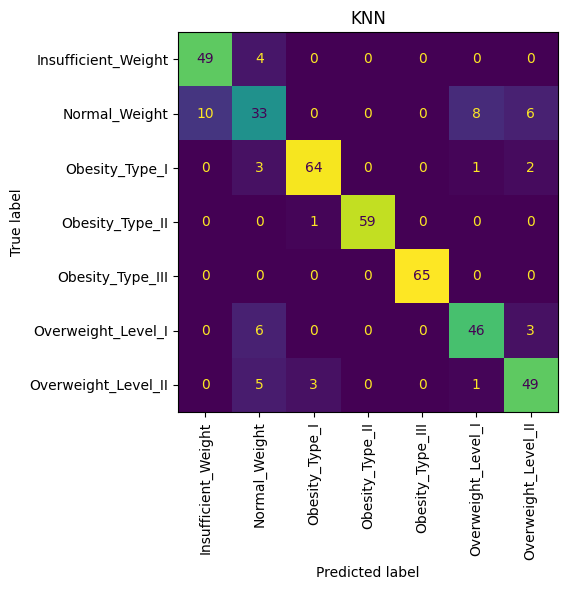

In [102]:

# Let's see the error matrix

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(y_test, pred_knn, xticks_rotation=90, ax=ax, colorbar=False)

ax.set_title("KNN")
plt.tight_layout()
plt.show()